# 04 · Dependencia con la concentración de ATP

Estudiaremos cómo cambia la velocidad media observada al variar la concentración de ATP. Se usan múltiples trayectorias por concentración para estimar la variabilidad estocástica.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.analysis.parameter_sweep import sweep_atp_concentration
from protein_motor_sim.visualization.plots import plot_atp_sweep

motor = Kinesin1()
simulator = GillespieSimulator()
environment = Environment(temperature_K=310.0, external_force_N=0.0)
atp_values_M = np.geomspace(1.0e-5, 5.0e-3, 7)

## 1. Ejecutar el barrido

In [3]:
results = sweep_atp_concentration(
    simulator=simulator,
    motor=motor,
    environment=environment,
    concentrations_M=atp_values_M,
    t_max=0.5,
    n_runs=25,
    seed=2026,
)

for row in results:
    print(
        f"[ATP]={row['atp_concentration_M']:.3e} M | "
        f"v={row['mean_velocity_nm_s']:.2f} ± "
        f"{row['std_velocity_nm_s']:.2f} nm/s"
    )

[ATP]=1.000e-05 M | v=65.60 ± 26.78 nm/s
[ATP]=2.817e-05 M | v=135.65 ± 51.75 nm/s
[ATP]=7.937e-05 M | v=213.40 ± 33.26 nm/s
[ATP]=2.236e-04 M | v=300.90 ± 51.78 nm/s
[ATP]=6.300e-04 M | v=339.83 ± 53.26 nm/s
[ATP]=1.775e-03 M | v=339.81 ± 112.68 nm/s
[ATP]=5.000e-03 M | v=376.64 ± 68.48 nm/s


## 2. Graficar el resultado

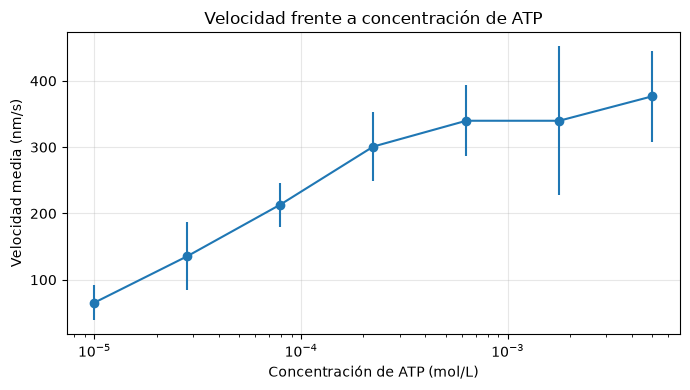

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_atp_sweep(results, ax=ax)
ax.set_xscale("log")
plt.tight_layout()
plt.show()

## 3. Interpretación y limitaciones

La velocidad se calcula sobre la ventana observada de cada trayectoria. Las corridas que no se desprenden antes de `t_max` son observaciones censuradas, no recorridos completos. En el modelo actual la concentración de ATP modifica directamente la tasa de unión de ATP; aún no hemos ajustado la curva a datos experimentales ni incorporado saturación por todos los pasos limitantes.